# 01 — Classification Metrics: Confusion Matrix, Precision/Recall/F1, ROC-AUC vs PR-AUC

**Overview:** build a confusion matrix by hand on a deliberately imbalanced dataset, derive
every classification metric from it, then compare ROC-AUC and PR-AUC under that same imbalance.

**Required libraries:** `numpy`, `matplotlib`, `scikit-learn`.

Connects to: `08_classification` (same models, now evaluated properly) and `11_generalization`
(train/validation discipline). Leads to: `02_ranking_metrics.ipynb`.

## 0. Environment & a deliberately imbalanced dataset

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, roc_curve, average_precision_score,
                              precision_recall_curve)

X, y = make_classification(n_samples=2000, n_features=10, n_informative=5,
                            weights=[0.95, 0.05], random_state=42)   # 95%/5% imbalance
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print("class balance (test):", np.bincount(y_test) / len(y_test))
model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
y_pred = model.predict(X_test)
y_scores = model.predict_proba(X_test)[:, 1]


class balance (test): [0.94666667 0.05333333]


## 1. Confusion matrix, by hand and via sklearn

⚠️ **Common Mistake:** reporting accuracy alone on this data. A model that always predicts the
majority class gets ~95% accuracy while catching ZERO positives.

In [2]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print("confusion matrix:\n", cm)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

# Derive every metric below from these four numbers by hand.
accuracy_manual = (tp + tn) / (tp + tn + fp + fn)
precision_manual = tp / (tp + fp) if (tp + fp) > 0 else 0.0
recall_manual = tp / (tp + fn) if (tp + fn) > 0 else 0.0
specificity_manual = tn / (tn + fp) if (tn + fp) > 0 else 0.0
f1_manual = 2 * precision_manual * recall_manual / (precision_manual + recall_manual) if (precision_manual + recall_manual) > 0 else 0.0

print(f"\naccuracy:    {accuracy_manual:.3f}")
print(f"precision:   {precision_manual:.3f}")
print(f"recall:      {recall_manual:.3f}")
print(f"specificity: {specificity_manual:.3f}")
print(f"F1:          {f1_manual:.3f}")

assert np.isclose(accuracy_manual, accuracy_score(y_test, y_pred))
assert np.isclose(precision_manual, precision_score(y_test, y_pred))
assert np.isclose(recall_manual, recall_score(y_test, y_pred))
assert np.isclose(f1_manual, f1_score(y_test, y_pred))
print("\nmanual calculations match sklearn.metrics exactly.")


confusion matrix:
 [[566   2]
 [ 31   1]]
TN=566, FP=2, FN=31, TP=1

accuracy:    0.945
precision:   0.333
recall:      0.031
specificity: 0.996
F1:          0.057

manual calculations match sklearn.metrics exactly.


## 2. The majority-class baseline, to make the accuracy trap concrete

In [3]:
majority_baseline_pred = np.zeros_like(y_test)   # always predict the majority (negative) class
baseline_accuracy = accuracy_score(y_test, majority_baseline_pred)
baseline_recall = recall_score(y_test, majority_baseline_pred, zero_division=0)

print(f"majority-class baseline: accuracy={baseline_accuracy:.3f}, recall={baseline_recall:.3f}")
print(f"actual model:            accuracy={accuracy_manual:.3f}, recall={recall_manual:.3f}")
print("\nThe baseline's accuracy looks deceptively close to a real model's -- but its recall is "
      "exactly 0: it never catches a single positive case.")

assert baseline_recall == 0.0
assert baseline_accuracy > 0.9   # the accuracy trap, made concrete


majority-class baseline: accuracy=0.947, recall=0.000
actual model:            accuracy=0.945, recall=0.031

The baseline's accuracy looks deceptively close to a real model's -- but its recall is exactly 0: it never catches a single positive case.


## 3. ROC-AUC vs PR-AUC under imbalance

💡 **Intuition:** ROC-AUC's x-axis (false positive rate) is normalized by the (huge) negative
class, so it stays deceptively high even when precision on the rare positive class is poor.
PR-AUC has no such normalization and tends to drop more sharply under imbalance.

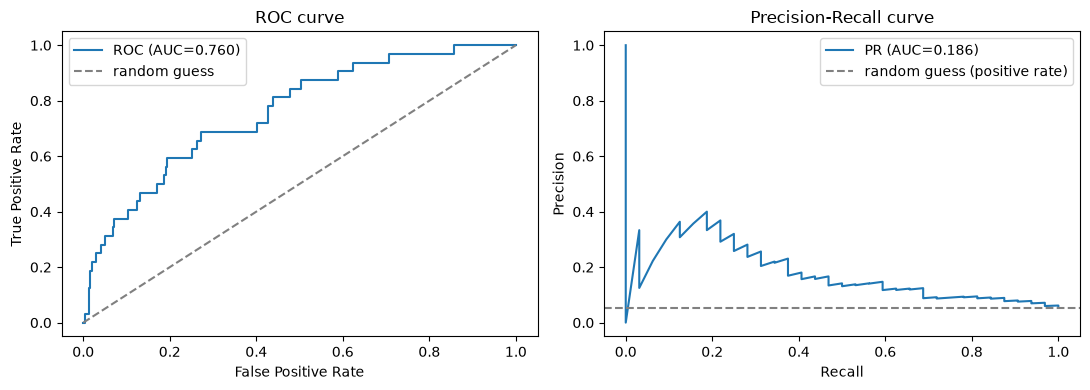

ROC-AUC: 0.760
PR-AUC:  0.186

ROC-AUC often looks strong even under heavy imbalance; PR-AUC is the more honest signal here because it's sensitive to how well the model does specifically on the rare positive class.


In [4]:
roc_auc = roc_auc_score(y_test, y_scores)
pr_auc = average_precision_score(y_test, y_scores)

fpr, tpr, _ = roc_curve(y_test, y_scores)
precision_curve, recall_curve, _ = precision_recall_curve(y_test, y_scores)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(fpr, tpr, label=f"ROC (AUC={roc_auc:.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="random guess")
axes[0].set_xlabel("False Positive Rate"); axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC curve"); axes[0].legend()

axes[1].plot(recall_curve, precision_curve, label=f"PR (AUC={pr_auc:.3f})")
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="random guess (positive rate)")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"ROC-AUC: {roc_auc:.3f}")
print(f"PR-AUC:  {pr_auc:.3f}")
print("\nROC-AUC often looks strong even under heavy imbalance; PR-AUC is the more honest "
      "signal here because it's sensitive to how well the model does specifically on the rare "
      "positive class.")

assert roc_auc > pr_auc   # the expected pattern under this kind of imbalance


## 4. Connection to what's next

`02_ranking_metrics.ipynb` picks up where threshold-based classification metrics stop being the
right tool — for ranked results (search, recommendations), you need Precision@K/MRR/MAP/NDCG
instead.

## 5. Interview questions
1. Walk through why a majority-class baseline can have high accuracy but zero recall.
2. Why does ROC-AUC tend to look more optimistic than PR-AUC under heavy class imbalance?
3. If false positives are very costly (e.g. flagging a legitimate transaction as fraud), which metric would you prioritize?
4. If false negatives are very costly (e.g. missing an actual disease case), which would you prioritize?
5. Why is F1 not always the right single-number summary, compared to reporting precision and recall separately?

## 6. Exercises
1. Vary the imbalance ratio in `make_classification`'s `weights` parameter and observe how the ROC-AUC/PR-AUC gap changes.
2. Pick a classification threshold other than 0.5 (e.g. 0.2) and recompute precision/recall — show the tradeoff.
3. Compute the majority-class baseline's PR-AUC and compare it to the real model's PR-AUC.

## 7. Summary

✅ Accuracy alone is dangerous under imbalance; precision/recall/F1 and especially PR-AUC give a
far more honest picture of a classifier on rare positive classes. Next:
`02_ranking_metrics.ipynb`.